In [1]:
import ast
import pandas as pd 
import matplotlib.pyplot as plt 

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

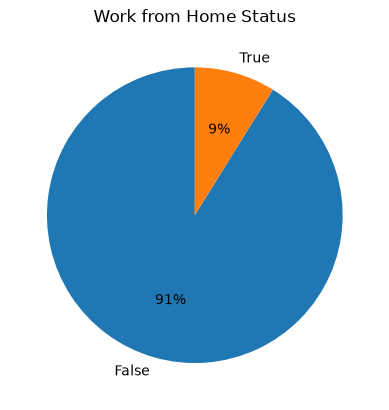

In [14]:
df['job_work_from_home'].value_counts().plot(kind='pie', startangle=90, autopct='%1.0f%%')
plt.title('Work from Home Status')
plt.ylabel('')
plt.show()

In [15]:
df[['job_work_from_home', 'job_no_degree_mention', 'job_health_insurance']]


,job_work_from_home,job_no_degree_mention,job_health_insurance
0,False,False,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False
...,...,...,...
785736,False,False,False
785737,False,False,False
785738,False,False,False
785739,False,False,False


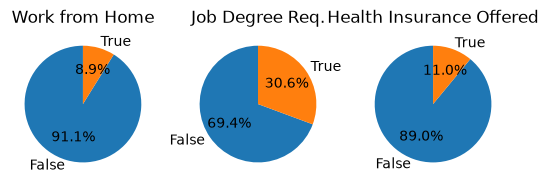

In [22]:
fig, ax = plt.subplots(1, 3)

dict_column = {
    'job_work_from_home': 'Work from Home',
    'job_no_degree_mention': 'Job Degree Req.',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(), startangle=90, autopct='%1.1f%%', labels=['False', 'True'])
    ax[i].set_title(title)
    
plt.show()

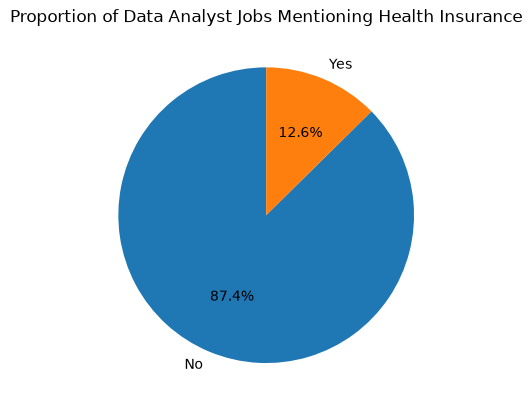

In [28]:
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()
df_DA_health = df_DA.groupby('job_health_insurance').size()
plt.pie(df_DA_health, labels=['No', 'Yes'], startangle=90, autopct='%1.1f%%')
plt.title('Proportion of Data Analyst Jobs Mentioning Health Insurance')
plt.show()

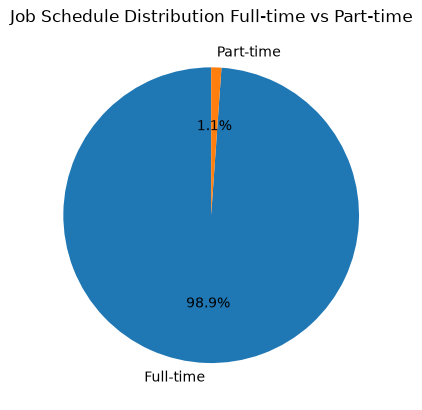

In [34]:
job_schedule_list = ['Full-time', 'Part-time']
df_job_schedule = df.groupby('job_schedule_type').size()[job_schedule_list]
plt.pie(df_job_schedule, labels=job_schedule_list, startangle=90, autopct='%1.1f%%')
plt.title('Job Schedule Distribution Full-time vs Part-time')
plt.show()

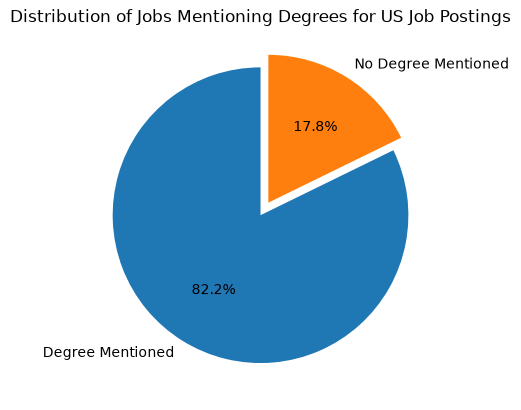

In [43]:
df_US = df[df['job_country'] == 'United States']['job_no_degree_mention'].value_counts()
plt.pie(df_US, explode=(0,0.1), startangle=90, autopct='%1.1f%%', labels=['Degree Mentioned', 'No Degree Mentioned'])
plt.title('Distribution of Jobs Mentioning Degrees for US Job Postings')
plt.show()